# 06 · Step 2: spatial deformation

The second shape change: a random **affine** transform (rotation, zoom, shear, translation) plus
a smooth **elastic** displacement. It runs on the HR grid, with nearest-neighbour sampling of
the labels.

Code: `nxgen/online/spatial.py`, `nxgen/core/geometry.py`, `nxgen/core/bspline.py`.
Config section: `spatial`.

In [2]:
from _setup import *
from nxgen.online import spatial as S
from nxgen.core import bspline
from nxgen.core.geometry import affine_matrix, rotation_matrix
from nxgen.core.config import load_config
import phantoms

## 1. The model

For every voxel `v` of the output HR grid, the label is read from the template at

$$x = (v - c)\,h \qquad p = M\,x + t + e(v) \qquad \text{src} = p / h + c$$

* `h` HR voxel size, `c` centre of the template (voxels), `x` position in *voxel-axis mm*;
* `M = R · S · Z`: rotation (`R = Rx Ry Rz`, degrees), shear (upper triangular, entries xy, xz,
  yz), zoom (diagonal);
* `t` translation (mm);
* `e(v)` elastic displacement (mm), a cubic B-spline of `n × n × n` random control vectors;
* `src` is rounded to the nearest voxel (labels are never interpolated); outside the template →
  background.

This is a **pull-back**: for each *output* voxel we compute where to read. That is what makes it
possible to compute only a patch (section 5).

Transforms use voxel-axis millimetres: they do not depend on the orientation stored in the
NIfTI affine.

In [3]:
print('R(0, 0, 90)  =\n', rotation_matrix([0, 0, 90]).round(3))
print('M with zoom 1.1 and shear xy 0.1 =\n', affine_matrix([0, 0, 0], [1.1, 1.1, 1.1], [0.1, 0, 0]).round(3))

R(0, 0, 90)  =
 [[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]]
M with zoom 1.1 and shear xy 0.1 =
 [[1.1  0.11 0.  ]
 [0.   1.1  0.  ]
 [0.   0.   1.1 ]]


## 2. Drawing a deformation: `sample`

Every per-axis parameter is drawn once per axis from its spec. The elastic control vectors are
drawn in `U(-dmax, dmax)` mm per component.

In [5]:
cfg = load_config(spatial=dict(rotation_deg=[-15, 15], zoom=[0.9, 1.1], shear=[-0.05, 0.05],
                               translation_mm=[-2, 2], elastic_dmax_mm=3.0,
                               elastic_ctrl={'randint': [3, 6]}))['spatial']
p = S.sample(cfg, np.random.default_rng(1))
for k, v in p.items():
    if k == 'elastic_ctrl_mm':
        a = np.asarray(v)
        print(f'{k:16s} array {a.shape}, range [{a.min():.2f}, {a.max():.2f}] mm')
    else:
        print(f'{k:16s} {np.round(v, 3).tolist() if isinstance(v, list) else v}')

rotation_deg     [0.355, 13.514, -10.675]
zoom             [1.09, 0.962, 0.985]
shear            [0.033, -0.009, 0.005]
translation_mm   [-1.89, 1.014, 0.153]
matrix           [[1.041, 0.203, 0.222], [-0.2, 0.94, 0.001], [-0.251, -0.043, 0.959]]
elastic_dmax_mm  3.0
elastic_ctrl_mm  array (6, 6, 6, 3), range [-2.99, 2.99] mm


`identity_params()` gives "no deformation" (used when `plan['spatial']` is `None`).

## 3. The elastic field: cubic B-splines

The `n` control points of an axis are spread evenly over the **whole** template. The field at a
voxel is a weighted sum of control values, with cubic B-spline weights:

$$e(v) = \sum_{a,b,c} W_x[v_x, a]\, W_y[v_y, b]\, W_z[v_z, c]\, \text{ctrl}[a, b, c]$$

The weights of each voxel are normalised to sum to 1 and are non-negative, so the field is a
**convex combination** of the control values: if all control values are in `[-dmax, dmax]`,
so is the field. The same code makes the bias field (notebook 09).

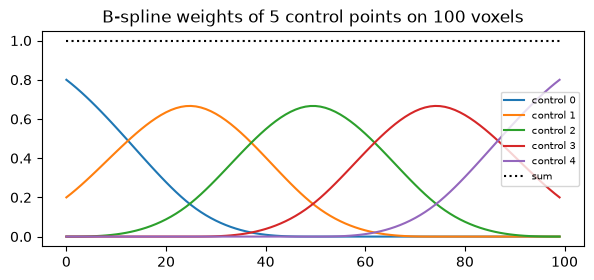

In [4]:
n, N = 5, 100
w = bspline.axis_weights(n, torch.arange(N), N)
plt.figure(figsize=(7, 2.8))
for j in range(n):
    plt.plot(w[:, j], label=f'control {j}')
plt.plot(w.sum(1), 'k:', label='sum')
plt.legend(fontsize=7); plt.title(f'B-spline weights of {n} control points on {N} voxels'); plt.show()

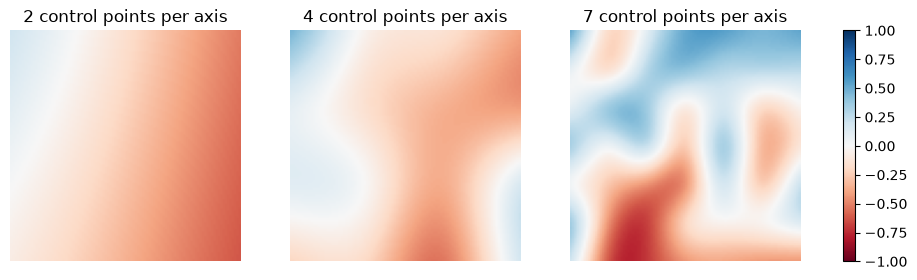

In [5]:
torch.manual_seed(0)
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for i, n in enumerate((2, 4, 7)):
    ctrl = torch.rand(n, n, 1, 1) * 2 - 1
    f = bspline.evaluate(ctrl, bspline.axis_weights(n, torch.arange(100), 100),
                         bspline.axis_weights(n, torch.arange(100), 100),
                         bspline.axis_weights(1, torch.arange(1), 1))[:, :, 0, 0]
    im = ax[i].imshow(f.T, origin='lower', cmap='RdBu', vmin=-1, vmax=1)
    ax[i].set_title(f'{n} control points per axis'); ax[i].axis('off')
plt.colorbar(im, ax=ax, fraction=0.02); plt.show()

Fewer control points → smoother field. `elastic_ctrl = {"randint": [2, 7]}` mixes both.

## 4. Applying it on a phantom

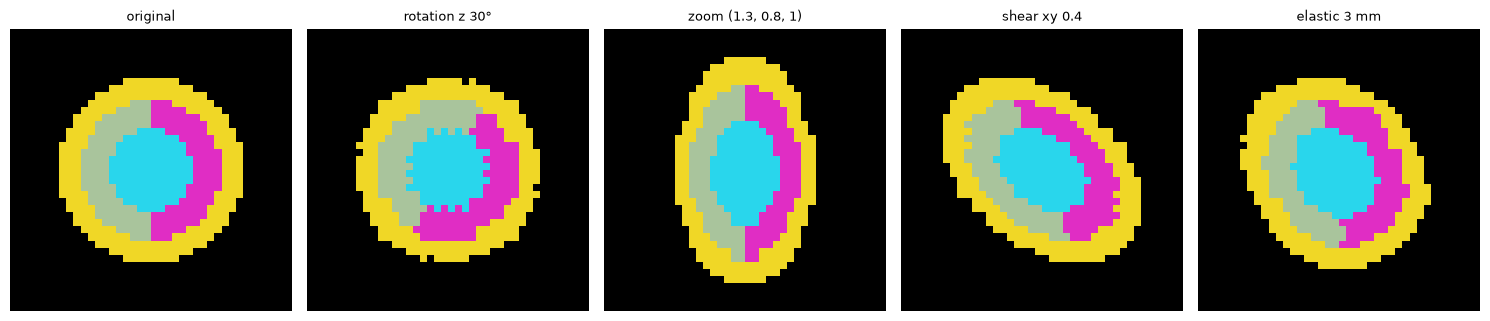

In [12]:
tree = phantoms.tree()
from nxgen.core.label_space import LabelSpace
seg = phantoms.sphere_labels((40, 40, 40))
ls = LabelSpace.build(tree, set(np.unique(seg).tolist()))
lab = ls.lut(int(seg.max()))[torch.as_tensor(seg)]
shape = list(lab.shape)

def deform(params):
    lo, hi = S.source_box(params, [0, 0, 0], shape, shape, 0.5)
    crop = lab[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
    return S.apply(crop, lo, params, [0, 0, 0], shape, shape, 0.5)

rot = dict(S.identity_params(), matrix=affine_matrix([0, 0, 30], [1, 1, 1], [0, 0, 0]).tolist())
zoom = dict(S.identity_params(), matrix=affine_matrix([0, 0, 0], [1.3, 0.8, 1], [0, 0, 0]).tolist())
shear = dict(S.identity_params(), matrix=affine_matrix([0, 0, 0], [1, 1, 1], [0.4, 0, 0]).tolist())
ctrl = np.random.default_rng(0).uniform(-3, 3, (4, 4, 4, 3))
elastic = dict(S.identity_params(), elastic_ctrl_mm=ctrl.tolist(), elastic_dmax_mm=3.0)
show([lab, deform(rot), deform(zoom), deform(shear), deform(elastic)],
     ['original', 'rotation z 30°', 'zoom (1.3, 0.8, 1)', 'shear xy 0.4', 'elastic 3 mm'])

A zoom > 1 *reads* further from the centre, so the content looks **smaller** (it is the inverse
map). The same holds for rotations: the content turns by −30°.

## 5. Only what is needed: `source_box`

`source_box(params, start, size, shape, h, halo)` returns the box of the template that the
output region `[start, start + size)` reads. It is **exact**, not an estimate:

* the affine maps the box of the region to a parallelepiped, bounded by its 8 corners;
* `|e| <= max |control value|` (convex combination, section 3).

The pipeline crops the template to this box (+ the morphology halo) before the morphology step.
Below: the source box of a patch, drawn on the template.

output region: [6, 10, 3] -> [22, 22, 23]
source box   : [0, 0, 0] -> [31, 29, 33]


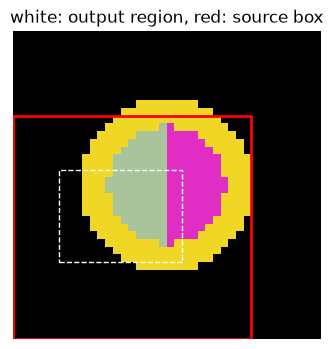

In [13]:
p = S.sample(cfg, np.random.default_rng(3))
start, size = [6, 10, 3], [16, 12, 20]
lo, hi = S.source_box(p, start, size, shape, 0.5)
print('output region:', start, '->', [s + n for s, n in zip(start, size)])
print('source box   :', lo.tolist(), '->', hi.tolist())
img = ls.lut(50)[torch.as_tensor(seg)].numpy()[:, :, 13].T
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(label_colors(len(ls))[img], origin="lower")
ax.add_patch(plt.Rectangle((lo[0] - .5, lo[1] - .5), hi[0] - lo[0], hi[1] - lo[1], fill=False, color='r', lw=2))
ax.add_patch(plt.Rectangle((start[0] - .5, start[1] - .5), size[0], size[1], fill=False, color='w', ls='--'))
ax.set_title('white: output region, red: source box'); ax.axis('off'); plt.show()

## 6. A patch is exactly the crop of the full deformation

patch == crop of full volume: True
full_roi_after == inner: True


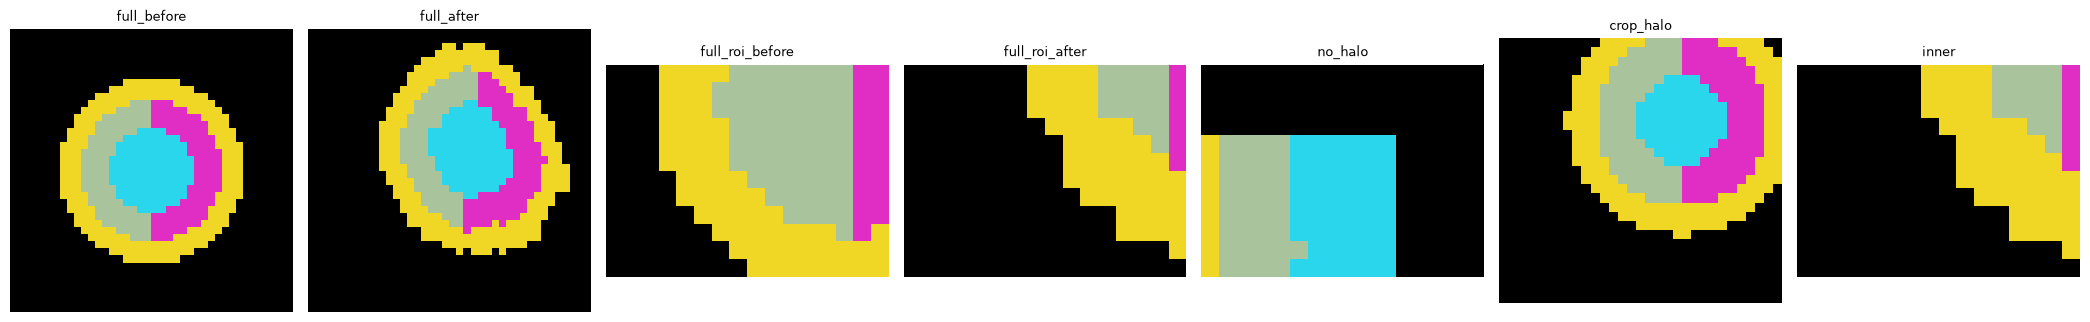

In [23]:
full = S.apply(lab, [0, 0, 0], p, [0, 0, 0], shape, shape, 0.5)
crop = lab[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
part = S.apply(crop, lo, p, start, size, shape, 0.5, slab_voxels=1000)
print('patch == crop of full volume:',
      torch.equal(part, full[6:22, 10:22, 3:23]))

full_roi_before = lab[start[0]:start[0]+size[0], start[1]:start[1]+size[1], start[2]:start[2]+size[2]]
full_roi_after = full[start[0]:start[0]+size[0], start[1]:start[1]+size[1], start[2]:start[2]+size[2]]
no_halo = S.apply(lab[start[0]:start[0]+size[0], start[1]:start[1]+size[1], start[2]:start[2]+size[2]], lo, p, start, size, shape, 0.5, slab_voxels=1000)
inner = part
print("full_roi_after == inner:", torch.equal(full_roi_after, inner))
show([lab, full, full_roi_before, full_roi_after, no_halo, crop, inner],
     ['full_before', 'full_after', 'full_roi_before', 'full_roi_after', 'no_halo', 'crop_halo', 'inner'])

`slab_voxels` sets how many output voxels are computed at once (memory). Results do not depend
on it (here it forces many slabs).

## 7. On the real template

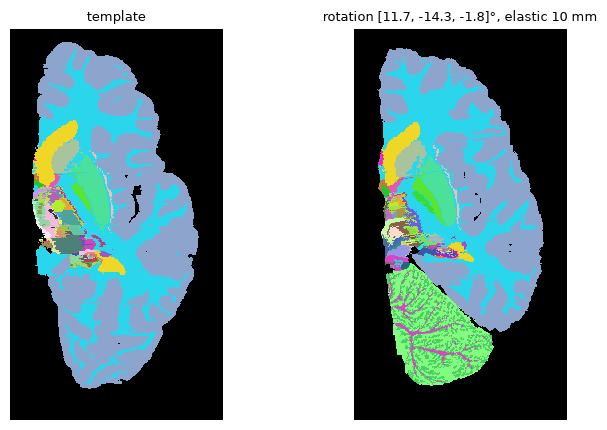

In [15]:
from nxgen import Generator, Recorder
ensure_template()
gen = Generator([TEMPLATE], load_config(CONFIG, spatial=dict(rotation_deg=[-15, 15],
                                                              elastic_dmax_mm=10.0)),
                device=DEVICE)
plan = gen.sample_plan(2)
rec = Recorder(steps=['morphology', 'spatial'])
gen.render(dict(plan, morphology=None), rec)
show([rec.steps['morphology'], rec.steps['spatial']],
     ['template', f"rotation {np.round(plan['spatial']['rotation_deg'], 1).tolist()}°, elastic 10 mm"],
     labels=[True, True], size=4)

## 8. Notes

* Labels are resampled with nearest neighbour; everything outside the template becomes
  background. Keep a template margin (notebook 03) that covers the deformations you configure.
* The elastic field is evaluated directly at the HR voxels, slab by slab: no coarse grid and no
  upsampling (v2 needed `field_voxel_mm` for memory; it is gone).
* All parameters (matrix, translation, control vectors) are in the plan, so a deformation can be
  inspected or replayed exactly.